[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/subjects.ipynb)

# Several subjects

Most studies record several people or several runs. This notebook shows the data formats `timecorr` accepts, the three ways to correlate a list of subjects (`autofc`, `isfc`, `wisfc`), and the functions that combine subjects' results, including a test at each timepoint.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.1 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr>=0.3.1" polars || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master" polars

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
plt.style.use('timecorr.tutorial')
COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']

## 1. Data formats

Each subject is a timepoints-by-features table (a NumPy array, a pandas DataFrame or a polars DataFrame), and a list holds one table per subject in any mix of formats. `tc.format_data` shows what `timecorr` works with, a list of float arrays.

In [3]:
import pandas as pd
import polars as pl

rng = np.random.default_rng(0)
array = rng.standard_normal((200, 4))
frame = pd.DataFrame(array, columns=['a', 'b', 'c', 'd'])
polars_frame = pl.DataFrame(array, schema=['a', 'b', 'c', 'd'])

formatted = tc.format_data([array, frame, polars_frame])
print([type(x).__name__ + str(x.shape) for x in formatted])
same = [np.array_equal(tc.timecorr(x), tc.timecorr(array)) for x in (frame, polars_frame)]
print('pandas and polars give the same result as NumPy:', same)

['ndarray(200, 4)', 'ndarray(200, 4)', 'ndarray(200, 4)']
pandas and polars give the same result as NumPy: [True, True]


## 2. Within or across subjects

We simulate two groups of 10 subjects with the same true correlations. In the first, each subject's activity is an independent draw; in the second (`subject_noise=0.5`), the subjects share one draw plus their own noise.

In [4]:
T, K = 300, 8
kernel = {'weights_params': {'var': 100}}
groups = {}
for name, noise in [('independent activity', None), ('shared activity', 0.5)]:
    subjects, corrs = tc.simulate_data(datagen='block', S=10, T=T, K=K, B=3, return_corrs=True,
                                       subject_noise=noise, set_random_seed=2)
    groups[name] = (subjects, corrs[0])
print({g: f'{len(s)} subjects, each {s[0].shape}' for g, (s, _) in groups.items()})

{'independent activity': '10 subjects, each (300, 8)', 'shared activity': '10 subjects, each (300, 8)'}


**`cfun` with a list of subjects**

- `tc.autofc`: each subject's own features;
- `tc.isfc` (the default): each subject with the mean of the others (inter-subject functional connectivity), which keeps only shared activity;
- `tc.wisfc`: like `isfc`, with the others weighted by how similar their correlations are.

In [5]:
def score(est, truth):
    return np.corrcoef(est[:, K:].ravel(), truth[:, K:].ravel())[0, 1]

cfuns = {'autofc': tc.autofc, 'isfc': tc.isfc, 'wisfc': tc.wisfc}
results = {}
for g, (subjects, truth) in groups.items():
    for c, cfun in cfuns.items():
        results[g, c] = tc.timecorr(subjects, cfun=cfun, combine=tc.corrmean_combine, **kernel)
        print(f'{g:21s} {c:7s} score {score(results[g, c], truth):5.2f}, '
              f'mean |r| {np.abs(results[g, c][:, K:]).mean():.2f}')

independent activity  autofc  score  0.97, mean |r| 0.25
independent activity  isfc    score  0.05, mean |r| 0.05
independent activity  wisfc   score  0.04, mean |r| 0.05
shared activity       autofc  score  0.86, mean |r| 0.21
shared activity       isfc    score  0.86, mean |r| 0.23
shared activity       wisfc   score  0.86, mean |r| 0.23


The score is the correlation between the estimated and true correlations. With independent activity, only `autofc` finds the shared correlations; ISFC is near zero. With shared activity, all three find them.

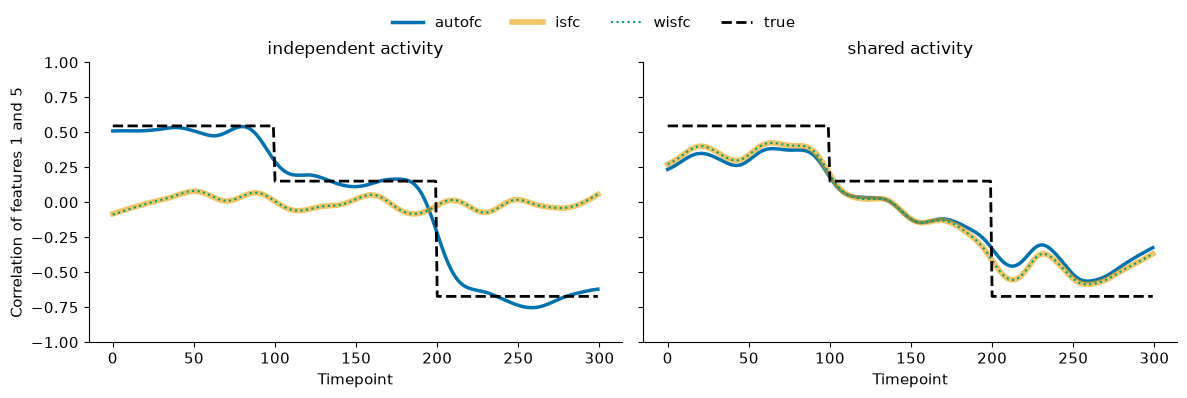

In [6]:
iu = np.triu_indices(K, 1)
truth = groups['shared activity'][1]
pair = np.argmax(np.ptp(tc.vec2mat(truth)[iu[0], iu[1]], axis=1))
i, j = iu[0][pair], iu[1][pair]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, g in zip(axes, groups):
    for c, style in zip(cfuns, [dict(lw=2.5), dict(lw=4, alpha=0.6), dict(lw=1.5, ls=':')]):
        ax.plot(tc.vec2mat(results[g, c])[i, j], label=c, **style)
    ax.plot(tc.vec2mat(groups[g][1])[i, j], color='k', ls='--', lw=2, label='true')
    ax.set(title=g, xlabel='Timepoint', ylim=(-1, 1))
axes[0].set_ylabel(f'Correlation of features {i} and {j}')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=4,
           bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
plt.show()

## 3. Combining subjects

`tc.null_combine` (the default) returns one result per subject. `tc.corrmean_combine` averages in Fisher z space (`r2z`, average, `z2r`) and `tc.mean_combine` takes the plain mean. `tc.tstat_combine` gives a one-sample t-test against 0 at every entry, with the p-values when `return_pvals=True`.

In [7]:
from timecorr.helpers import r2z, z2r

subjects, truth = groups['independent activity']
each = tc.timecorr(subjects, cfun=tc.autofc, combine=tc.null_combine, **kernel)
print('null_combine:', len(each), 'arrays of', each[0].shape)
default = tc.timecorr(subjects, cfun=tc.autofc, **kernel)
print('null_combine is the default:', all(np.array_equal(a, b) for a, b in zip(each, default)))
for f in (tc.corrmean_combine, tc.mean_combine):
    print(f'{f.__name__}:', tc.timecorr(subjects, cfun=tc.autofc, combine=f, **kernel).shape)

by_hand = z2r(np.mean([r2z(x) for x in each], axis=0))
print('corrmean_combine equals z2r(mean(r2z)):', np.allclose(tc.corrmean_combine(each), by_hand))
t_stat, p = tc.tstat_combine(each, return_pvals=True)
print('tstat_combine: t', t_stat.shape, ', p', p.shape)

null_combine: 10 arrays of (300, 36)
null_combine is the default: True
corrmean_combine: (300, 36)
mean_combine: (300, 36)
corrmean_combine equals z2r(mean(r2z)): True
tstat_combine: t (300, 36) , p (300, 36)


The t-test at each timepoint asks whether a correlation differs from zero across subjects, and we correct for the number of timepoints (Bonferroni). Neighboring timepoints share most of their kernel weights, so their tests are not independent and the correction is conservative.

timepoints with corrected p < 0.05: 196 of 300


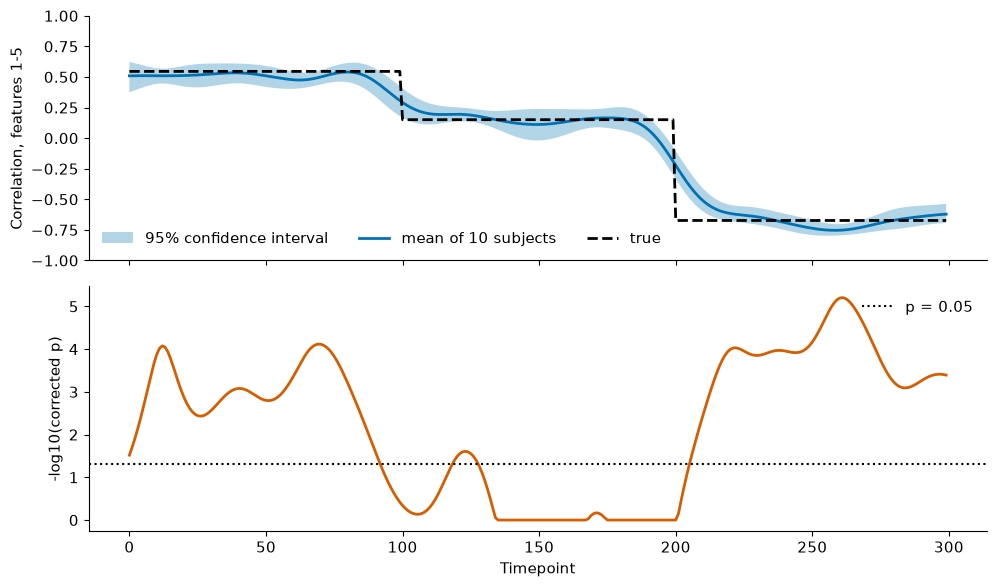

In [8]:
col = K + pair  # column of the pair (i, j) in the vectorized output
p_bonf = np.minimum(p[:, col] * T, 1)
print(f'timepoints with corrected p < 0.05: {(p_bonf < 0.05).sum()} of {T}')

z = np.array([r2z(x[:, col]) for x in each])
sem = z.std(0, ddof=1) / np.sqrt(len(z))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].fill_between(np.arange(T), z2r(z.mean(0) - 1.96 * sem), z2r(z.mean(0) + 1.96 * sem),
                     alpha=0.3, label='95% confidence interval')
axes[0].plot(z2r(z.mean(0)), lw=2, label='mean of 10 subjects')
axes[0].plot(tc.vec2mat(truth)[i, j], color='k', ls='--', lw=2, label='true')
axes[0].set(ylabel=f'Correlation, features {i}-{j}', ylim=(-1, 1))
axes[0].legend(loc='lower left', ncol=3)
axes[1].plot(-np.log10(p_bonf), color=COLORS[3], lw=2)
axes[1].axhline(-np.log10(0.05), color='k', ls=':', label='p = 0.05')
axes[1].set(xlabel='Timepoint', ylabel='-log10(corrected p)')
axes[1].legend(loc='upper right')
fig.tight_layout()
plt.show()

Next: [reducing the number of features](reduce.ipynb).

The picture on this tutorial's card in the gallery: the correlation of one pair of features in each of 10 subjects (thin) and their mean (thick).

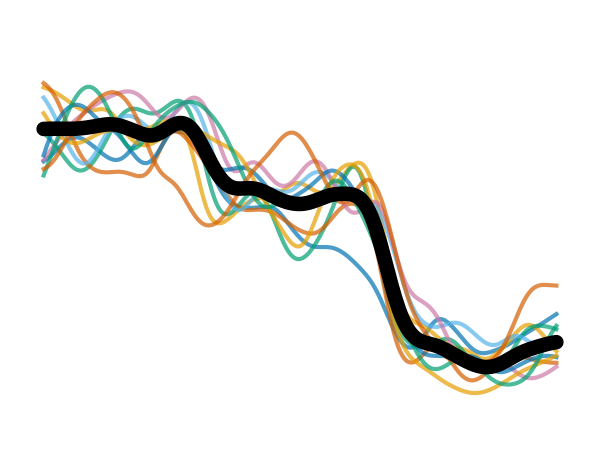

In [9]:
import io
from IPython.display import Image, display

fig = plt.figure(figsize=(4, 3), facecolor='white')
ax = fig.add_axes([0.03, 0.06, 0.94, 0.88])
for s, x in enumerate(each):
    ax.plot(x[:, col], color=COLORS[s % 6], lw=2, alpha=0.7)
ax.plot(z2r(z.mean(0)), color='k', lw=7, solid_capstyle='round')
ax.set_ylim(-1.05, 1.05)
ax.set_axis_off()
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, facecolor='white')
plt.close(fig)
display(Image(buf.getvalue()))